# 09 — Mudanças graduais de −50% a +50%, em passos de 5%

> **Modelo congelado:** `scale_pos_weight=13.882494684620836`, corte de decisão 0,50. O Booster e o manifesto estão em `models/`; as quatro tabelas produzidas ficam em `results/tables/`.

**Perguntas.** Em cada variável e par, (1) qual mudança foi *pedida*, (2) quanto drift ela *realmente criou* e (3) como Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo reagiram quando há rótulos válidos? A grade é $-50,-45,\ldots,-5,+5,\ldots,+45,+50\%$.

Há dois mecanismos com interpretações distintas:

1. **Mix/reponderação:** aumenta ou reduz a participação relativa de perfis **já observados**. Mantém $X$, $Y$ e score de cada linha juntos; mede as quatro métricas no holdout rotulado sob a hipótese de estabilidade de $P(Y\mid X)$ e suporte histórico. Para pares, mudamos as duas margens altas em quatro combinações de sinais usando ajuste proporcional iterativo (IPF) da tabela 2×2; as linhas completas permanecem juntas.
2. **Valores sintéticos:** multiplica uma ou duas entradas por $1+r$ no mesmo registro. Mede PSI, score e decisões que cruzam 0,50. Os rótulos históricos **não são desfechos contrafactuais** após mudar renda, idade ou atrasos; portanto não calculamos Brier/AUC/PR-AUC/KS de desempenho nessa trilha.

`cs-test.csv` não possui rótulos. O holdout de 15% do arquivo de treino é aleatório, não fora do tempo. **Nenhuma métrica recebe um limiar de aprovação ou critério de parada aqui.** As tabelas de trajetória e de maior deterioração observada são descritivas e condicionadas aos mecanismos e à grade; sem materialidade de negócio não existe uma única “tolerância” universal.

**Como reproduzir em outro contexto:** congele um modelo e um holdout rotulado; defina mecanismos plausíveis e unidades de mudança; fixe a grade e bins de referência antes de olhar respostas; execute os cenários com/sem $Y$ conforme a validade do desfecho; registre intensidade solicitada, intensidade realizada, drift, quatro métricas centrais e ESS; visualize curvas por direção e mecanismo; confirme em períodos futuros rotulados.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1. Dicionário, fórmulas e unidades

| Nome | Definição | Leitura |
|---|---|---|
| PSI | $\sum_b(q_b-p_b)\log(q_b/p_b)$ após suavização de 0,5 observação por faixa. $p_b$ e $q_b$ são proporções no bin $b$ da referência e cenário. | Distância descritiva, sem sinal nem corte universal; **não é porcentagem**. |
| Brier | $\sum_i w_i(y_i-\hat p_i)^2/\sum_i w_i$. $y_i\in\{0,1\}$, $\hat p_i$ é o score, $w_i$ é o peso. | Erro quadrático de probabilidade; menor é melhor; depende da composição/prevalência e calibração. |
| AUC ROC | Área de trapézios da curva taxa de verdadeiros positivos (TPR) versus taxa de falsos positivos (FPR) ao variar o corte. | Discriminação; maior é melhor. |
| PR-AUC trapezoidal | Área de trapézios da curva **precisão versus recall** ao variar o corte. | Maior é melhor; sensível à prevalência. |
| AP (*average precision*) | Soma em degraus da precisão nos incrementos de recall. | Informação adicional. **AP e PR-AUC trapezoidal são cálculos diferentes.** |
| KS do modelo | $\max_t[\mathrm{TPR}(t)-\mathrm{FPR}(t)]$, variando o corte $t$. | Separação entre classes; maior é melhor. Não confundir com KS de drift de uma entrada. |
| Recall/precisão em 0,50 | $TP/(TP+FN)$ e $TP/(TP+FP)$ no corte fixo. | Referências operacionais descritivas, sem parar a grade. |
| ESS | $(\sum_i w_i)^2/\sum_i w_i^2$. | Tamanho efetivo aproximado; pesos concentrados reduzem suporte. |

No mix univariado, $h_i=1$ indica o grupo alto, $p=P(h=1)$ é a participação basal e $q=p(1+r)$ é a participação pedida para intensidade relativa $r$. O peso é $w_i=q/p$ se $h_i=1$ e $(1-q)/(1-p)$ caso contrário. **+5% relativo** transforma $p=20\%$ em $q=21\%$, não 25%. Para pares, o IPF ajusta duas margens da tabela 2×2 conservando os registros dentro de cada célula. A mudança percentual solicitada não é o PSI gerado.

Nos valores, $x_i'=x_i(1+r)$ para valores observados; contagens e idade são arredondadas. Uma contagem 1 pode continuar 1 até muitos passos: `n_alterados`, mudança média realizada e PSI mostram o efeito real. O PSI separa ausentes, zero, negativos e quantis positivos. As curvas unem **cenários**, não datas.

In [2]:
from pathlib import Path
from itertools import combinations, product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from IPython.display import display

# Funciona se o kernel iniciar na raiz do projeto ou dentro de notebooks//.
ROOT = DATA_DIR_PROJECT
if not (ROOT / 'cs-training.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'cs-training.csv').exists(), 'Inicie o notebook da raiz do projeto ou da pasta notebooks/.'
OUT = TABLES_DIR
manifest = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
FEATURES = manifest['features']
TARGET = manifest['target']
CUTOFF = float(manifest['cutoff'])
MAGNITUDES = tuple(np.arange(5, 51, 5) / 100)
STEPS = tuple(np.r_[-np.array(MAGNITUDES)[::-1], MAGNITUDES])
assert len(STEPS) == 20 and np.isclose(STEPS[0], -.5) and np.isclose(STEPS[-1], .5)
SEED = 33
# O notebook 00 documenta o custo de reconstrução do modelo em CPU.
model_class = xgb.Booster(model_file=str(MODEL_DIR / 'model_class_retreinado.json'))
model_class.set_param({'device':'cpu'})
assert model_class.feature_names == FEATURES, 'Ordem das features diferente da do modelo.'
print('XGBoost:', xgb.__version__, '| features:', len(FEATURES), '| corte:', CUTOFF)

XGBoost: 3.0.0 | features: 10 | corte: 0.5


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 2. Reconstituir o holdout e congelar a linha de base

Repetimos o split do `model_final.ipynb`: 15% para teste, semente 33, sem estratificação. O mesmo Booster é usado em todos os cenários. Antes da grade, calculamos as quatro métricas centrais e as referências de recall/precisão no corte 0,50. Previsões usam todas as árvores serializadas, como o manifesto.

In [4]:
raw = pd.read_csv(ROOT / 'cs-training.csv').drop(columns=['Unnamed: 0'])
X_all = raw[FEATURES]
y_all = raw[TARGET].astype(int)
X_tv, X_hold, y_tv, y_hold = train_test_split(X_all, y_all, test_size=0.15, random_state=SEED)
X_train, _, _, _ = train_test_split(X_tv, y_tv, test_size=0.1765, random_state=SEED)
SUPPORT_MIN = X_train[FEATURES].min()
SUPPORT_MAX = X_train[FEATURES].max()
X_hold = X_hold.reset_index(drop=True)
y_hold = y_hold.reset_index(drop=True)

def predict(frame):
    dm = xgb.DMatrix(frame[FEATURES], feature_names=FEATURES, enable_categorical=True)
    return model_class.predict(dm)

score_hold = predict(X_hold)
assert len(X_hold) == 22500
print('Holdout:', len(X_hold), '| eventos:', int(y_hold.sum()),
      '| prevalência:', round(y_hold.mean(), 4))

Holdout: 22500 | eventos: 1500 | prevalência: 0.0667


## 3. Funções de métricas e PSI

Os limites das faixas são calculados **apenas na referência**. Tratamos zero e ausentes separadamente, algo especialmente útil nas variáveis de atraso e renda. Para valores positivos, usamos até dez faixas por quantis, com cortes repetidos removidos. Assim, PSI pode ter números de faixas diferentes conforme a variável; sua comparação direta entre variáveis exige cuidado. Os dados de crédito incluem valores de utilização e razão da dívida acima de 1, portanto não os truncamos em 1.

In [5]:
def bin_spec(reference, n_quantiles=10):
    a = np.asarray(reference, dtype=float)
    positive = a[np.isfinite(a) & (a > 0)]
    if len(positive) == 0:
        return np.array([], dtype=float)
    return np.unique(np.quantile(positive, np.linspace(0, 1, n_quantiles + 1)[1:-1]))

def bin_codes(values, edges):
    a = np.asarray(values, dtype=float)
    code = np.zeros(len(a), dtype=int)  # 0: ausente ou não finito
    finite = np.isfinite(a)
    code[finite & (a == 0)] = 1
    code[finite & (a < 0)] = 2
    pos = finite & (a > 0)
    code[pos] = 3 + np.searchsorted(edges, a[pos], side='right')
    return code

def psi_codes(ref_codes, new_codes, weights=None):
    k = max(int(np.max(ref_codes)), int(np.max(new_codes))) + 1
    p = np.bincount(ref_codes, minlength=k).astype(float)
    if weights is None:
        q = np.bincount(new_codes, minlength=k).astype(float)
    else:
        w = np.asarray(weights, dtype=float)
        w = w * (len(w) / w.sum())
        q = np.bincount(new_codes, weights=w, minlength=k).astype(float)
    p = (p + 0.5) / (p.sum() + 0.5 * k)
    q = (q + 0.5) / (q.sum() + 0.5 * k)
    return float(np.sum((q - p) * np.log(q / p)))

def psi_feature(reference, scenario, weights=None):
    edges = bin_spec(reference)
    return psi_codes(bin_codes(reference, edges), bin_codes(scenario, edges), weights)

def psi_joint_high(reference_a, reference_b, new_a, new_b, weights=None):
    cut_a = high_cut(reference_a)
    cut_b = high_cut(reference_b)
    def joint(a, b):
        return (np.asarray(a, dtype=float) > cut_a).astype(int) * 2 + (np.asarray(b, dtype=float) > cut_b).astype(int)
    return psi_codes(joint(reference_a, reference_b), joint(new_a, new_b), weights)

def weighted_metrics(y, score, weights=None):
    y = np.asarray(y, dtype=int)
    p = np.asarray(score, dtype=float)
    w = np.ones(len(y)) if weights is None else np.asarray(weights, dtype=float)
    assert len(y)==len(p)==len(w) and np.all(w>=0) and w.sum()>0
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w)
    prec_curve, rec_curve, _ = precision_recall_curve(y, p, sample_weight=w)
    decision = p >= CUTOFF
    tp = np.sum(w * (decision & (y == 1)))
    fp = np.sum(w * (decision & (y == 0)))
    positives = np.sum(w * (y == 1))
    return {
        'auc_roc': float(auc(fpr, tpr)),
        'prauc_trap': float(auc(rec_curve, prec_curve)),
        'ks_modelo': float(np.max(tpr - fpr)),
        'ap': float(-np.sum(np.diff(rec_curve) * prec_curve[:-1])),
        'brier': float(np.average((y - p) ** 2, weights=w)),
        'prevalencia': float(np.average(y, weights=w)),
        'score_medio': float(np.average(p, weights=w)),
        'taxa_acima_corte': float(np.average(decision, weights=w)),
        'precisao_no_corte': tp / (tp + fp) if tp + fp else np.nan,
        'recall_no_corte': tp / positives if positives else np.nan,
        'n_efetivo': float(w.sum() ** 2 / np.sum(w ** 2)),
    }

baseline = weighted_metrics(y_hold, score_hold)
display(pd.DataFrame([baseline]).round(5))
assert np.isclose(baseline['auc_roc'], manifest['baseline_holdout']['auc_roc'], atol=1e-6)
assert np.isclose(baseline['prauc_trap'], manifest['baseline_holdout']['pr_auc_trap'], atol=1e-6)
assert np.isclose(baseline['ks_modelo'], manifest['baseline_holdout']['ks_modelo'], atol=1e-6)
assert np.isclose(baseline['brier'], manifest['baseline_holdout']['brier'], atol=1e-6)

,auc_roc,prauc_trap,ks_modelo,ap,brier,prevalencia,score_medio,taxa_acima_corte,precisao_no_corte,recall_no_corte,n_efetivo
0,0.86684,0.39599,0.58771,0.39639,0.14404,0.06667,0.324,0.24591,0.21525,0.794,22500.0


## 4. Mix univariado: grupo alto de −50% a +50%

Para cada variável, `high_flag` marca o grupo acima do percentil 75; se esse percentil é zero, usa valores positivos. Ausentes ficam no complemento. Aplicamos os **20 passos** da grade na participação relativa desse grupo. Linhas, rótulos e scores individuais permanecem intactos; os pesos mudam a composição da população simulada. Por isso as quatro métricas são calculáveis sob a hipótese de estabilidade de $P(Y\mid X)$, mas não representam observação futura. `psi_max_outras` revela drift colateral em outras entradas pela seleção de perfis completos. `n_efetivo` indica concentração de pesos.

In [6]:
def high_cut(values):
    a = np.asarray(values, dtype=float)
    q = float(np.nanquantile(a, 0.75))
    return 0.0 if q <= 0 else float(np.nextafter(q, -np.inf))

def high_flag(values):
    a = np.asarray(values, dtype=float)
    return np.isfinite(a) & (a > high_cut(a))

def mix_weights(flag, relative_change):
    flag = np.asarray(flag, dtype=bool)
    p = flag.mean()
    q = p * (1 + relative_change)
    if not (0 < p < 1 and 0 < q < 1):
        raise ValueError('Grupo alto sem suporte ou participação-alvo inválida.')
    return np.where(flag, q / p, (1 - q) / (1 - p)), p, q

def mix_result(flag, r):
    w, p, q = mix_weights(flag, r)
    m = weighted_metrics(y_hold, score_hold, w)
    m.update({
        'mudanca_relativa_pct': 100 * r,
        'participacao_base': p,
        'participacao_alvo': q,
        'participacao_realizada': np.average(flag, weights=w),
        'psi_score': psi_feature(score_hold, score_hold, w),
        'delta_auc_roc': m['auc_roc'] - baseline['auc_roc'],
        'delta_prauc_trap': m['prauc_trap'] - baseline['prauc_trap'],
        'delta_ks_modelo': m['ks_modelo'] - baseline['ks_modelo'],
        'delta_ap': m['ap'] - baseline['ap'],
        'delta_brier': m['brier'] - baseline['brier'],
        'delta_taxa_acima_corte': m['taxa_acima_corte'] - baseline['taxa_acima_corte'],
    })
    return w, m

rows = []
for feature in FEATURES:
    flag = high_flag(X_hold[feature])
    for r in STEPS:
        w, result = mix_result(flag, r)
        result['variavel'] = feature
        result['limiar_grupo_alto'] = high_cut(X_hold[feature])
        result['n_grupo_alto'] = int(flag.sum())
        result['psi_variavel'] = psi_feature(X_hold[feature], X_hold[feature], w)
        result['psi_max_outras'] = max(
            psi_feature(X_hold[f], X_hold[f], w) for f in FEATURES if f != feature
        )
        rows.append(result)
mix_uni = pd.DataFrame(rows)
mix_uni.to_csv(OUT / 'resultados_percentuais_mix_univariado.csv', index=False)
display(mix_uni[['variavel','mudanca_relativa_pct','participacao_base','participacao_realizada',
                 'psi_variavel','psi_max_outras','delta_brier','delta_auc_roc',
                 'delta_prauc_trap','delta_ks_modelo',
                 'n_efetivo']].round(5).head(12))
assert len(mix_uni)==10*20
print('Cenários de mix univariado:', len(mix_uni))

,variavel,mudanca_relativa_pct,participacao_base,participacao_realizada,psi_variavel,psi_max_outras,delta_brier,delta_auc_roc,delta_prauc_trap,delta_ks_modelo,n_efetivo
0,RevolvingUtilizationOfUnsecuredLines,-50.0,0.25,0.1250,0.09256,0.00785,-0.03105,-0.00803,-0.05355,-0.00855,20769.23077
1,RevolvingUtilizationOfUnsecuredLines,-45.0,0.25,0.1375,0.07276,0.00619,-0.02795,-0.00636,-0.04621,-0.00722,21077.28337
2,RevolvingUtilizationOfUnsecuredLines,-40.0,0.25,0.1500,0.05594,0.00477,-0.02484,-0.00493,-0.03944,-0.00655,21360.75949
3,RevolvingUtilizationOfUnsecuredLines,-35.0,0.25,0.1625,0.04176,0.00357,-0.02174,-0.00372,-0.03319,-0.00503,21617.29384
4,RevolvingUtilizationOfUnsecuredLines,-30.0,0.25,0.1750,0.02998,0.00257,-0.01863,-0.00272,-0.02740,-0.00310,21844.66019
5,RevolvingUtilizationOfUnsecuredLines,-25.0,0.25,0.1875,0.02038,0.00175,-0.01553,-0.00190,-0.02202,-0.00162,22040.81633
6,RevolvingUtilizationOfUnsecuredLines,-20.0,0.25,0.2000,0.01278,0.00110,-0.01242,-0.00124,-0.01701,-0.00062,22203.94737
7,RevolvingUtilizationOfUnsecuredLines,-15.0,0.25,0.2125,0.00706,0.00061,-0.00932,-0.00073,-0.01233,0.00013,22332.50620
8,RevolvingUtilizationOfUnsecuredLines,-10.0,0.25,0.2250,0.00308,0.00026,-0.00621,-0.00037,-0.00796,0.00046,22425.24917
9,RevolvingUtilizationOfUnsecuredLines,-5.0,0.25,0.2375,0.00076,0.00007,-0.00311,-0.00012,-0.00385,0.00042,22481.26561


Cenários de mix univariado: 200


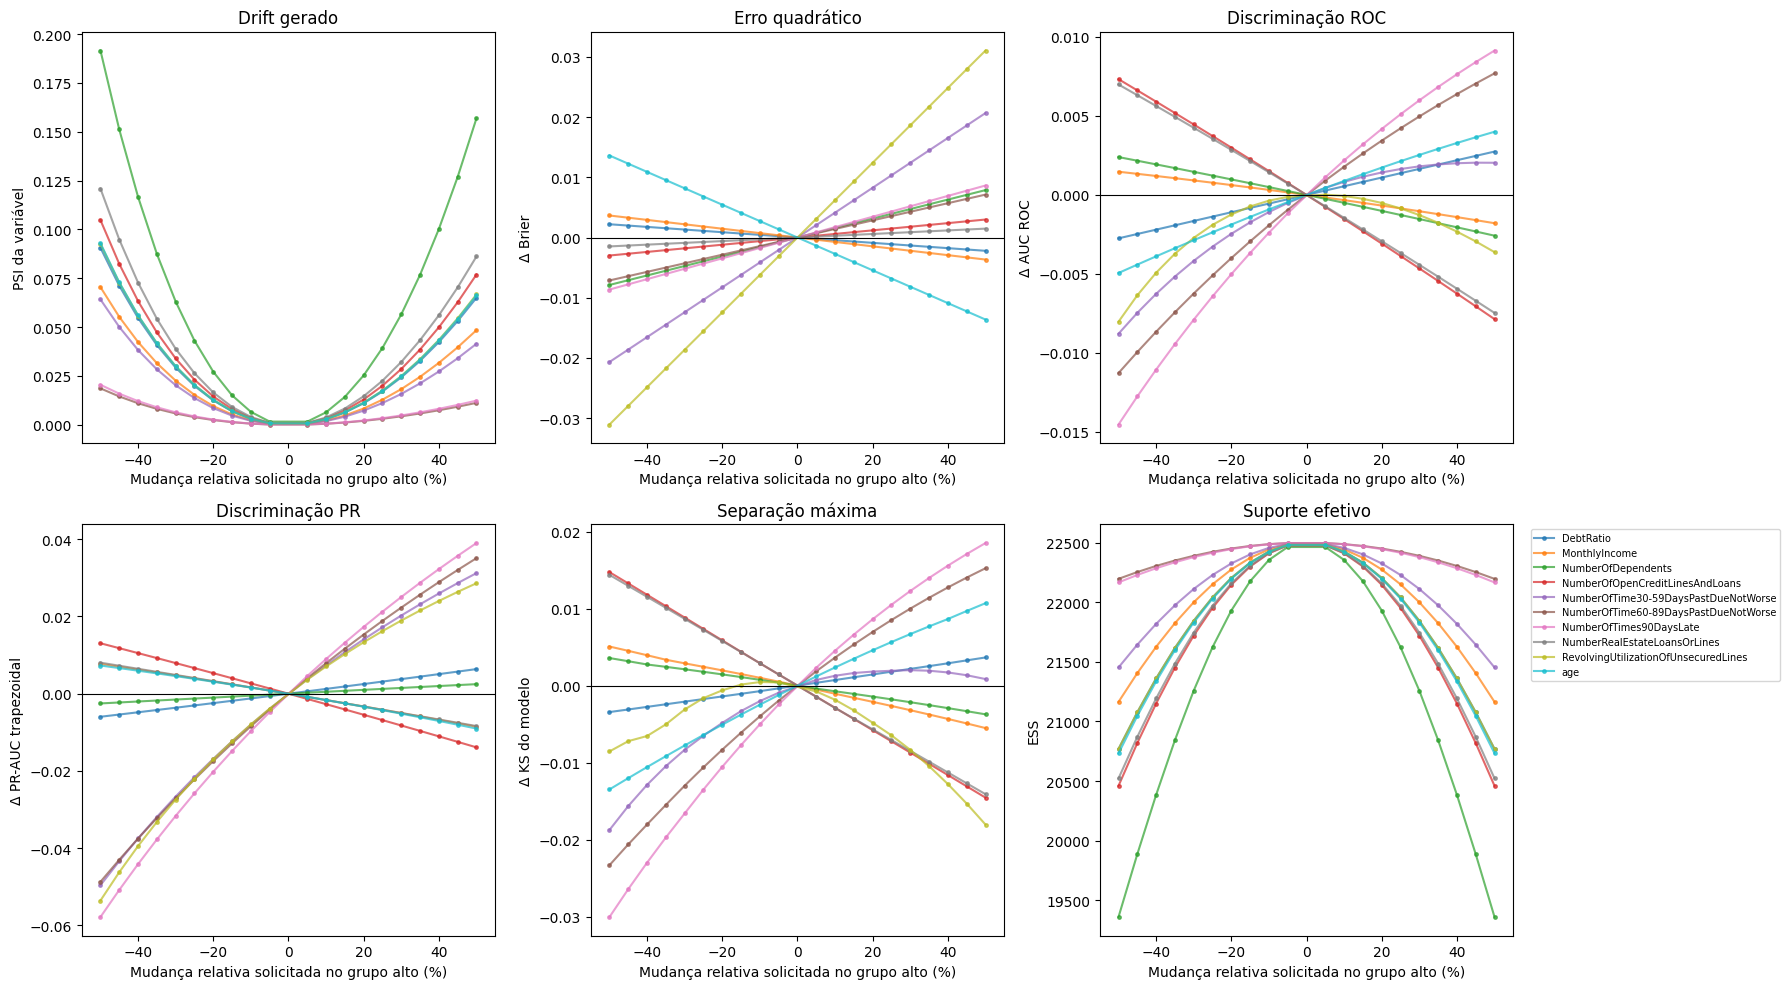

Legenda: cada linha é uma entrada; os 20 pontos vão de −50% a +50% em passos de 5%, sem 0. Δ = cenário menos baseline; Brier positivo e AUC/PR-AUC/KS negativos indicam deterioração. As linhas são trajetórias de cenários, não séries temporais.


In [7]:
# Intensidade aplicada, drift realizado e quatro respostas centrais.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
plot_spec=[('psi_variavel','PSI da variável','Drift gerado'),
           ('delta_brier','Δ Brier','Erro quadrático'),
           ('delta_auc_roc','Δ AUC ROC','Discriminação ROC'),
           ('delta_prauc_trap','Δ PR-AUC trapezoidal','Discriminação PR'),
           ('delta_ks_modelo','Δ KS do modelo','Separação máxima'),
           ('n_efetivo','ESS','Suporte efetivo')]
for ax,(column,ylabel,title) in zip(axes.flat,plot_spec):
    for feature,d in mix_uni.groupby('variavel'):
        d=d.sort_values('mudanca_relativa_pct')
        ax.plot(d['mudanca_relativa_pct'],d[column],marker='o',ms=2.5,alpha=.7,label=feature)
    if column.startswith('delta_'): ax.axhline(0,color='black',lw=.8)
    ax.set(xlabel='Mudança relativa solicitada no grupo alto (%)',ylabel=ylabel,title=title)
axes[1,2].legend(bbox_to_anchor=(1.03,1),loc='upper left',fontsize=7)
fig.tight_layout();plt.show()
print('Legenda: cada linha é uma entrada; os 20 pontos vão de −50% a +50% em passos de 5%, sem 0. '
      'Δ = cenário menos baseline; Brier positivo e AUC/PR-AUC/KS negativos indicam deterioração. '
      'As linhas são trajetórias de cenários, não séries temporais.')

## 5. Valores univariados: multiplicar a entrada por $1+r$

Os outros nove valores da linha ficam fixos. A direção pode ser assimétrica; contagens 0 permanecem 0 e contagens pequenas podem não mudar após arredondamento. Por isso mostramos percentual **realizado**, quantidade de linhas realmente alteradas, PSI da entrada, PSI do score e fração que cruza 0,50. Uma média alterada não garante drift em todos os quantis. O corte 0,50 permanece fixo.

**Sem Brier/AUC/PR-AUC/KS neste bloco:** o mesmo `y_hold` não descreve necessariamente o resultado que ocorreria se a característica real do cliente mudasse. Se o mecanismo específico for erro de medição sem alteração do risco verdadeiro, declare essa hipótese e use o notebook 12.
O CSV registra a fração de linhas com algum valor da entrada alterada fora do intervalo mínimo–máximo do **treino** e a diferença contra a referência. Esse intervalo é um diagnóstico estatístico, não uma regra suficiente de plausibilidade de crédito.


In [8]:
INTEGER_FEATURES = {'age', 'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'}

def change_values(frame, changes):
    out = frame.copy()
    for feature, r in changes.items():
        s = pd.to_numeric(out[feature], errors='coerce').astype(float)
        new = s * (1 + r)
        if feature in INTEGER_FEATURES:
            new = np.rint(new)
        out[feature] = new
    return out

def fraction_outside_training_support(frame, columns):
    # Fração de linhas com pelo menos uma entrada selecionada fora de [min,max] do TREINO.
    outside = np.zeros(len(frame), dtype=bool)
    for feature in columns:
        v = pd.to_numeric(frame[feature], errors='coerce').to_numpy(dtype=float)
        outside |= np.isfinite(v) & ((v < SUPPORT_MIN[feature]) | (v > SUPPORT_MAX[feature]))
    return float(outside.mean())

def realized_mean_change(original, changed):
    a = np.nanmean(np.asarray(original, dtype=float))
    b = np.nanmean(np.asarray(changed, dtype=float))
    return 100 * (b / a - 1) if a != 0 else np.nan

def response_metrics(ref_score, new_score):
    diff = np.abs(new_score - ref_score)
    return {
        'mudanca_absoluta_score_media': float(np.mean(diff)),
        'mudanca_absoluta_score_p95': float(np.quantile(diff, 0.95)),
        'troca_decisao': float(np.mean((ref_score >= CUTOFF) != (new_score >= CUTOFF))),
        'taxa_acima_corte': float(np.mean(new_score >= CUTOFF)),
        'delta_taxa_acima_corte': float(np.mean(new_score >= CUTOFF) - np.mean(ref_score >= CUTOFF)),
        'score_medio': float(np.mean(new_score)),
        'delta_score_medio': float(np.mean(new_score) - np.mean(ref_score)),
        'psi_score': psi_feature(ref_score, new_score),
    }

rows = []
for feature in FEATURES:
    for r in STEPS:
        scenario = change_values(X_hold, {feature: r})
        new_score = predict(scenario)
        result = response_metrics(score_hold, new_score)
        result.update({
            'variavel': feature,
            'mudanca_valor_solicitada_pct': 100 * r,
            'mudanca_media_realizada_pct': realized_mean_change(X_hold[feature], scenario[feature]),
            'psi_variavel': psi_feature(X_hold[feature], scenario[feature]),
            'n_alterados': int(np.sum(~np.isclose(X_hold[feature], scenario[feature], equal_nan=True))),
            'fora_suporte_treino_frac': fraction_outside_training_support(scenario,[feature]),
            'delta_fora_suporte_treino_frac': (fraction_outside_training_support(scenario,[feature])
                                               -fraction_outside_training_support(X_hold,[feature])),
        })
        rows.append(result)
valores_uni = pd.DataFrame(rows)
valores_uni.to_csv(OUT / 'resultados_percentuais_valores_univariado.csv', index=False)
display(valores_uni[['variavel','mudanca_valor_solicitada_pct','mudanca_media_realizada_pct',
                    'n_alterados','psi_variavel','mudanca_absoluta_score_media',
                    'troca_decisao','psi_score']].round(5).head(12))
assert len(valores_uni)==10*20
print('Cenários de valores univariados:', len(valores_uni))

,variavel,mudanca_valor_solicitada_pct,mudanca_media_realizada_pct,n_alterados,psi_variavel,mudanca_absoluta_score_media,troca_decisao,psi_score
0,RevolvingUtilizationOfUnsecuredLines,-50.0,-50.0,20843,0.78066,0.05152,0.08502,0.04883
1,RevolvingUtilizationOfUnsecuredLines,-45.0,-45.0,20843,0.70761,0.04526,0.07600,0.03852
2,RevolvingUtilizationOfUnsecuredLines,-40.0,-40.0,20843,0.67160,0.04068,0.07000,0.03175
3,RevolvingUtilizationOfUnsecuredLines,-35.0,-35.0,20843,0.63635,0.03526,0.05889,0.02248
4,RevolvingUtilizationOfUnsecuredLines,-30.0,-30.0,20843,0.57368,0.03101,0.05276,0.01825
5,RevolvingUtilizationOfUnsecuredLines,-25.0,-25.0,20843,0.26848,0.02541,0.04320,0.01220
6,RevolvingUtilizationOfUnsecuredLines,-20.0,-20.0,20843,0.25023,0.02009,0.03413,0.00834
7,RevolvingUtilizationOfUnsecuredLines,-15.0,-15.0,20843,0.24604,0.01407,0.02404,0.00364
8,RevolvingUtilizationOfUnsecuredLines,-10.0,-10.0,20843,0.23040,0.00883,0.01511,0.00109
9,RevolvingUtilizationOfUnsecuredLines,-5.0,-5.0,20843,0.20743,0.00487,0.00876,0.00019


Cenários de valores univariados: 200


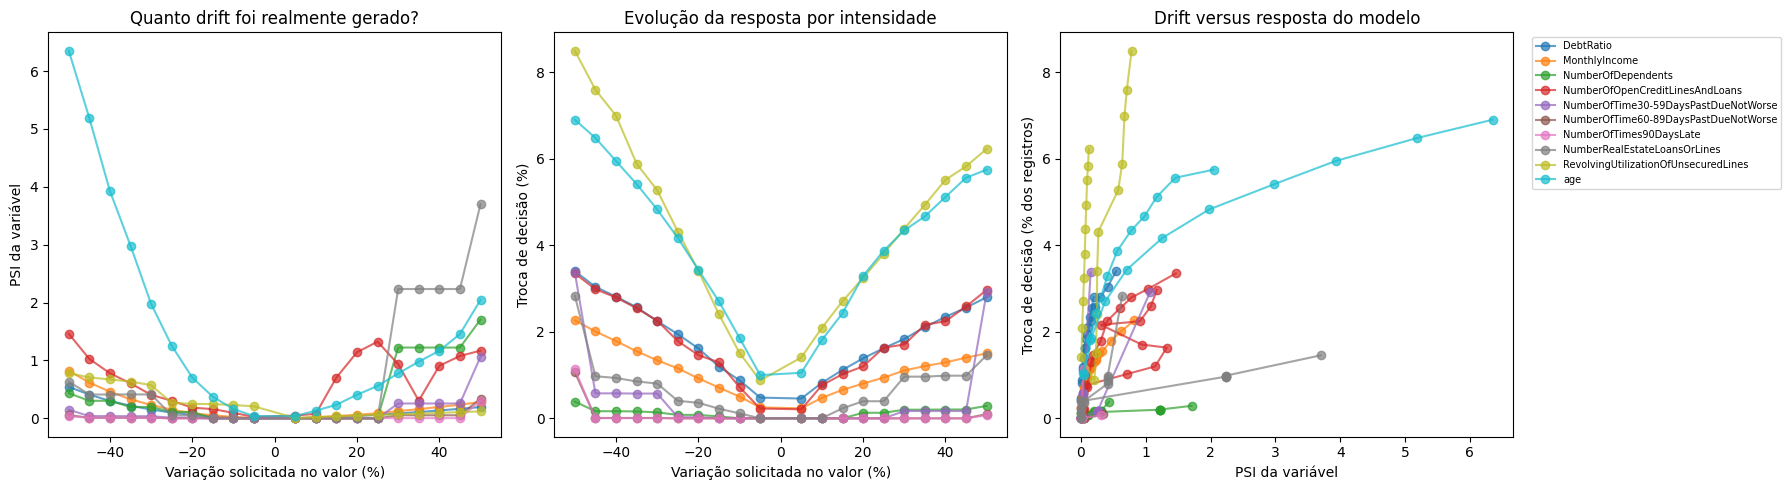

Legenda: cada linha é uma variável; os pontos seguem −50% a +50%. À direita, a posição mede drift observado e a altura mede troca de lado do corte 0,50. Não são métricas de performance. As linhas não representam tempo.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for feature, d in valores_uni.groupby('variavel'):
    d = d.sort_values('mudanca_valor_solicitada_pct')
    axes[0].plot(d['mudanca_valor_solicitada_pct'], d['psi_variavel'], 'o-', alpha=0.7, label=feature)
    axes[1].plot(d['mudanca_valor_solicitada_pct'], 100 * d['troca_decisao'], 'o-', alpha=0.7, label=feature)
    axes[2].plot(d['psi_variavel'], 100 * d['troca_decisao'], 'o-', alpha=0.7, label=feature)
axes[0].set(xlabel='Variação solicitada no valor (%)', ylabel='PSI da variável', title='Quanto drift foi realmente gerado?')
axes[1].set(xlabel='Variação solicitada no valor (%)', ylabel='Troca de decisão (%)', title='Evolução da resposta por intensidade')
axes[2].set(xlabel='PSI da variável', ylabel='Troca de decisão (% dos registros)', title='Drift versus resposta do modelo')
axes[2].legend(bbox_to_anchor=(1.03, 1), loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()
print('Legenda: cada linha é uma variável; os pontos seguem −50% a +50%. À direita, a posição mede drift observado e a altura mede troca de lado do corte 0,50. Não são métricas de performance. As linhas não representam tempo.')

## 6. Complemento discreto: transições graduais 0→1 e 1→0 nos atrasos

Multiplicar uma contagem inteira pequena por 1,05 e arredondar muitas vezes não altera o valor. Zeros continuam zero; códigos extremos 96/98 podem dominar a mudança média das contagens. Para testar a região usual sem alterar esses códigos, fazemos transições de 0 para 1 ou de 1 para 0 em **5%, 10%, …, 50% das linhas elegíveis**, em dez passos. O denominador é o número de linhas elegíveis daquela variável e direção, não toda a amostra. Usamos uma permutação fixa e subconjuntos aninhados: o cenário 10% contém as linhas do cenário 5%.

Isto é alteração **sintética de valores**. PSI, scores e trocas de decisão são calculáveis; Brier, AUC, PR-AUC e KS do modelo não são calculados com os rótulos antigos. No arquivo de resultados, `fracao_elegiveis_realizada_pct` informa o percentual efetivo após arredondar o número de linhas.

,variavel,direcao,fracao_elegiveis_solicitada_pct,fracao_elegiveis_realizada_pct,n_elegiveis,n_alterados,fracao_total_alterada_pct,psi_variavel,psi_score,mudanca_absoluta_score_media,troca_decisao
0,NumberOfTime30-59DaysPastDueNotWorse,0→1,5.0,4.99867,18825,941,4.18222,0.01560,0.00260,0.00876,0.00876
1,NumberOfTime30-59DaysPastDueNotWorse,0→1,10.0,9.99734,18825,1882,8.36444,0.05604,0.00994,0.01747,0.01729
2,NumberOfTime30-59DaysPastDueNotWorse,0→1,15.0,15.00133,18825,2824,12.55111,0.11581,0.02246,0.02618,0.02604
3,NumberOfTime30-59DaysPastDueNotWorse,0→1,20.0,20.00000,18825,3765,16.73333,0.19186,0.04037,0.03491,0.03462
4,NumberOfTime30-59DaysPastDueNotWorse,0→1,25.0,24.99867,18825,4706,20.91556,0.28266,0.06256,0.04355,0.04289
5,NumberOfTime30-59DaysPastDueNotWorse,0→1,30.0,30.00266,18825,5648,25.10222,0.38749,0.09022,0.05221,0.05111
6,NumberOfTime30-59DaysPastDueNotWorse,0→1,35.0,35.00133,18825,6589,29.28444,0.50582,0.12514,0.06097,0.05907
7,NumberOfTime30-59DaysPastDueNotWorse,0→1,40.0,40.00000,18825,7530,33.46667,0.63787,0.16130,0.06955,0.06862
8,NumberOfTime30-59DaysPastDueNotWorse,0→1,45.0,44.99867,18825,8471,37.64889,0.78415,0.20375,0.07823,0.07827
9,NumberOfTime30-59DaysPastDueNotWorse,0→1,50.0,49.99734,18825,9412,41.83111,0.94559,0.25786,0.08694,0.08649


Cenários executados: 60 | CSV: .\results\tables\resultados_transicoes_atraso.csv


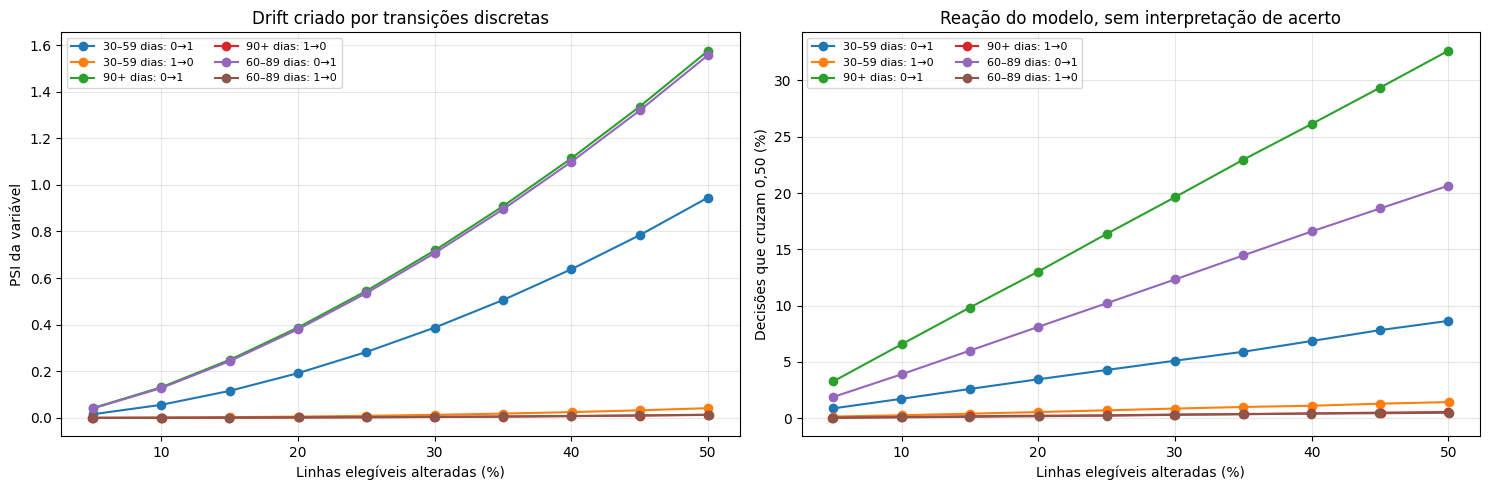

In [10]:
ATRASOS = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse',
]
FRACOES_ELEGIVEIS = MAGNITUDES
gerador_transicoes = np.random.default_rng(SEED + 903)
linhas_transicoes = []
for feature in ATRASOS:
    original = X_hold[feature].to_numpy(dtype=float)
    codigo_extremo = np.isin(original, [96., 98.])
    for origem, destino, direcao in [(0., 1., '0→1'), (1., 0., '1→0')]:
        elegiveis = np.flatnonzero(original == origem)
        assert len(elegiveis) > 0, (feature, direcao)
        ordem = gerador_transicoes.permutation(elegiveis)
        for fracao in FRACOES_ELEGIVEIS:
            n_sorteado = int(np.rint(fracao * len(elegiveis)))
            escolhidos = ordem[:n_sorteado]
            scenario = X_hold.copy()
            scenario.loc[escolhidos, feature] = destino
            assert np.array_equal(scenario[feature].to_numpy()[codigo_extremo], original[codigo_extremo])
            assert np.count_nonzero(scenario[feature].to_numpy() != original) == n_sorteado
            assert scenario.drop(columns=feature).equals(X_hold.drop(columns=feature))
            score_novo = predict(scenario)
            resultado = response_metrics(score_hold, score_novo)
            resultado.update({
                'variavel': feature,
                'direcao': direcao,
                'fracao_elegiveis_solicitada_pct': 100 * fracao,
                'fracao_elegiveis_realizada_pct': 100 * n_sorteado / len(elegiveis),
                'n_elegiveis': len(elegiveis),
                'n_alterados': n_sorteado,
                'fracao_total_alterada_pct': 100 * n_sorteado / len(X_hold),
                'psi_variavel': psi_feature(X_hold[feature], scenario[feature]),
                'n_codigos_96_98_intactos': int(codigo_extremo.sum()),
            })
            linhas_transicoes.append(resultado)
transicoes_atraso = pd.DataFrame(linhas_transicoes)
assert len(transicoes_atraso) == 3 * 2 * len(MAGNITUDES)
assert (transicoes_atraso['n_alterados'] > 0).all()
assert (transicoes_atraso['psi_variavel'] > 0).all()
assert not {'auc_roc','prauc_trap','ks_modelo','ap','brier'} & set(transicoes_atraso.columns)
ARQUIVO_TRANSICOES = OUT / 'resultados_transicoes_atraso.csv'
transicoes_atraso.to_csv(ARQUIVO_TRANSICOES, index=False)
display(transicoes_atraso[[
    'variavel','direcao','fracao_elegiveis_solicitada_pct',
    'fracao_elegiveis_realizada_pct','n_elegiveis','n_alterados',
    'fracao_total_alterada_pct','psi_variavel','psi_score',
    'mudanca_absoluta_score_media','troca_decisao'
]].round(5))
print('Cenários executados:', len(transicoes_atraso), '| CSV:', ARQUIVO_TRANSICOES)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
nomes_curtos = {
    ATRASOS[0]: '30–59 dias', ATRASOS[1]: '90+ dias', ATRASOS[2]: '60–89 dias',
}
for (feature, direcao), grupo in transicoes_atraso.groupby(['variavel','direcao'], sort=False):
    grupo = grupo.sort_values('fracao_elegiveis_solicitada_pct')
    rotulo = f'{nomes_curtos[feature]}: {direcao}'
    axes[0].plot(grupo['fracao_elegiveis_realizada_pct'], grupo['psi_variavel'], marker='o', label=rotulo)
    axes[1].plot(grupo['fracao_elegiveis_realizada_pct'], 100*grupo['troca_decisao'], marker='o', label=rotulo)
axes[0].set(xlabel='Linhas elegíveis alteradas (%)', ylabel='PSI da variável',
            title='Drift criado por transições discretas')
axes[1].set(xlabel='Linhas elegíveis alteradas (%)', ylabel='Decisões que cruzam 0,50 (%)',
            title='Reação do modelo, sem interpretação de acerto')
axes[0].legend(fontsize=8, ncol=2)
axes[1].legend(fontsize=8, ncol=2)
for ax in axes: ax.grid(alpha=.3)
fig.tight_layout(); plt.show()

## 7. Pares: 45 combinações × 4 direções × 10 intensidades

São $\binom{10}{2}=45$ pares. Para cada par, testamos `++`, `+-`, `-+` e `--` em 5%, 10%, …, 50% sobre **cada variável**. Assim cada trilha contém 1.800 cenários. Na trilha de mix, o perfil alto/baixo de cada variável é definido pelo mesmo corte univariado. Ajustamos a tabela conjunta 2×2 por **IPF** para que a participação alta da primeira e da segunda variável atinja, separadamente, $p_a(1+r_a)$ e $p_b(1+r_b)$. As quatro células mantêm suas linhas, scores e rótulos originais; o ajuste de linhas/colunas preserva a razão de chances da tabela agregada quando todas as células têm suporte. Isto é uma regra associativa de reponderação, não uma afirmação causal nem a preservação exata de todas as correlações entre dez entradas.

Registramos participações pedidas e realizadas, PSI de cada variável, **PSI conjunto 2×2**, drift máximo colateral das demais entradas e ESS. PSI conjunto resume só quatro perfis discretizados; não mede toda a dependência multivariada. Na trilha de valores, as quatro direções alteram simultaneamente as duas colunas em 5.000 linhas piloto; relações com outras entradas ficam fixas.

In [11]:
def pair_weights(flag_a, flag_b, ra, rb):
    # IPF ajusta as duas margens de uma tabela 2×2 com suporte observado positivo.
    fa=np.asarray(flag_a,dtype=bool); fb=np.asarray(flag_b,dtype=bool)
    assert len(fa)==len(fb)
    code=2*fa.astype(int)+fb.astype(int)
    p=np.bincount(code,minlength=4).astype(float).reshape(2,2)/len(code)
    if np.any(p==0): raise ValueError('Par com célula conjunta vazia: IPF exige suporte em 2×2.')
    pa=fa.mean(); pb=fb.mean()
    qa=pa*(1+ra); qb=pb*(1+rb)
    if not (0<qa<1 and 0<qb<1): raise ValueError('Participação-alvo fora de (0,1).')
    q=p.copy()
    for _ in range(200):
        q[1,:]*=qa/q[1,:].sum(); q[0,:]*=(1-qa)/q[0,:].sum()
        q[:,1]*=qb/q[:,1].sum(); q[:,0]*=(1-qb)/q[:,0].sum()
        if max(abs(q[1,:].sum()-qa),abs(q[:,1].sum()-qb))<1e-12: break
    assert np.isclose(q.sum(),1,atol=1e-10)
    assert np.isclose(q[1,:].sum(),qa,atol=1e-9)
    assert np.isclose(q[:,1].sum(),qb,atol=1e-9)
    w=(q/p).reshape(-1)[code]
    return w,p,q,pa,pb,qa,qb

pair_mix_rows=[]
for a,b in combinations(FEATURES,2):
    flag_a=high_flag(X_hold[a]); flag_b=high_flag(X_hold[b])
    for magnitude in MAGNITUDES:
        for sign_a,sign_b in product((-1,1),repeat=2):
            ra,rb=sign_a*magnitude,sign_b*magnitude
            w,p_joint,q_joint,pa,pb,qa,qb=pair_weights(flag_a,flag_b,ra,rb)
            m=weighted_metrics(y_hold,score_hold,w)
            m.update({
                'variavel_a':a,'variavel_b':b,
                'direcao':('+' if sign_a>0 else '-')+('+' if sign_b>0 else '-'),
                'intensidade_pct':100*magnitude,
                'mudanca_solicitada_a_pct':100*ra,'mudanca_solicitada_b_pct':100*rb,
                'participacao_alta_a_base':pa,'participacao_alta_a_alvo':qa,
                'participacao_alta_a_realizada':np.average(flag_a,weights=w),
                'participacao_alta_b_base':pb,'participacao_alta_b_alvo':qb,
                'participacao_alta_b_realizada':np.average(flag_b,weights=w),
                'n_celula_minima':int((p_joint.min()*len(flag_a)).round()),
                'psi_a':psi_feature(X_hold[a],X_hold[a],w),
                'psi_b':psi_feature(X_hold[b],X_hold[b],w),
                'psi_conjunto_2x2':psi_joint_high(X_hold[a],X_hold[b],X_hold[a],X_hold[b],w),
                'psi_max_outras':max(psi_feature(X_hold[f],X_hold[f],w)
                                      for f in FEATURES if f not in (a,b)),
                'psi_score':psi_feature(score_hold,score_hold,w),
                **{f'delta_{k}':m[k]-baseline[k] for k in
                   ['brier','auc_roc','prauc_trap','ks_modelo','ap']},
            })
            pair_mix_rows.append(m)
mix_pares=pd.DataFrame(pair_mix_rows)
assert len(mix_pares)==45*4*len(MAGNITUDES)
assert mix_pares[['variavel_a','variavel_b']].drop_duplicates().shape[0]==45
assert np.allclose(mix_pares.participacao_alta_a_alvo,mix_pares.participacao_alta_a_realizada,atol=1e-9)
assert np.allclose(mix_pares.participacao_alta_b_alvo,mix_pares.participacao_alta_b_realizada,atol=1e-9)
mix_pares.to_csv(OUT/'resultados_percentuais_mix_pares.csv',index=False)
display(mix_pares[['variavel_a','variavel_b','direcao','intensidade_pct',
                   'psi_a','psi_b','psi_conjunto_2x2','n_efetivo',
                   'delta_brier','delta_auc_roc','delta_prauc_trap','delta_ks_modelo']].round(5).head(12))
print('Cenários de mix em pares:',len(mix_pares))

,variavel_a,variavel_b,direcao,intensidade_pct,psi_a,psi_b,psi_conjunto_2x2,n_efetivo,delta_brier,delta_auc_roc,delta_prauc_trap,delta_ks_modelo
0,RevolvingUtilizationOfUnsecuredLines,age,--,5.0,0.00076,0.00074,0.00207,22454.11852,-0.00213,-0.00068,-0.00368,-0.00088
1,RevolvingUtilizationOfUnsecuredLines,age,-+,5.0,0.00081,0.00078,0.00144,22467.74371,-0.00379,0.00026,-0.00398,0.00132
2,RevolvingUtilizationOfUnsecuredLines,age,+-,5.0,0.00078,0.00080,0.00144,22467.74372,0.00380,-0.00039,0.00375,-0.00174
3,RevolvingUtilizationOfUnsecuredLines,age,++,5.0,0.00074,0.00072,0.00202,22454.11702,0.00211,0.00058,0.00344,0.00062
4,RevolvingUtilizationOfUnsecuredLines,age,--,10.0,0.00309,0.00300,0.00838,22317.34745,-0.00428,-0.00147,-0.00763,-0.00205
5,RevolvingUtilizationOfUnsecuredLines,age,-+,10.0,0.00328,0.00306,0.00576,22371.46292,-0.00758,0.00040,-0.00822,0.00220
6,RevolvingUtilizationOfUnsecuredLines,age,+-,10.0,0.00309,0.00325,0.00576,22371.46305,0.00762,-0.00088,0.00728,-0.00387
7,RevolvingUtilizationOfUnsecuredLines,age,++,10.0,0.00292,0.00282,0.00799,22317.29990,0.00420,0.00107,0.00665,0.00099
8,RevolvingUtilizationOfUnsecuredLines,age,--,15.0,0.00707,0.00688,0.01911,22092.31248,-0.00645,-0.00238,-0.01186,-0.00348
9,RevolvingUtilizationOfUnsecuredLines,age,-+,15.0,0.00750,0.00681,0.01300,22212.60339,-0.01136,0.00039,-0.01275,0.00262


Cenários de mix em pares: 1800


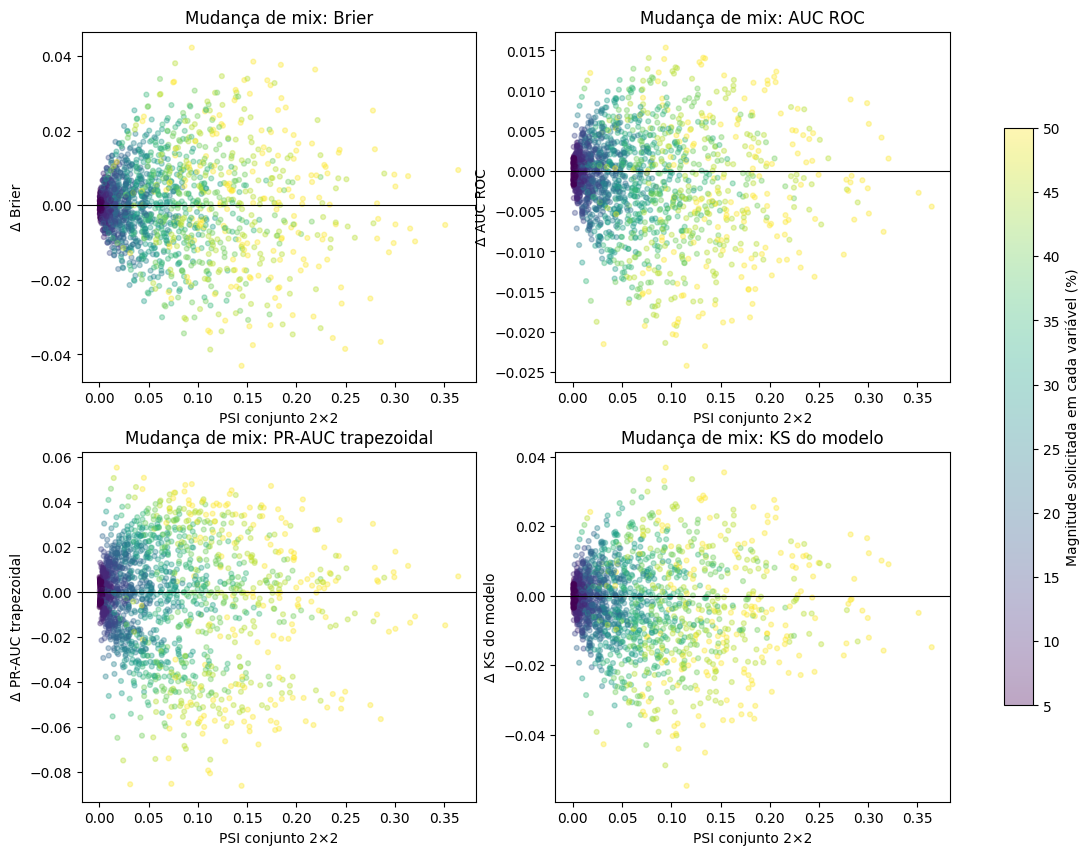

Legenda: cada ponto representa um dos 1.800 cenários (45 pares × 4 sinais × 10 magnitudes). PSI mede drift dos quatro perfis; o eixo vertical é cenário menos baseline. Mesma distância de PSI pode ter respostas distintas.


In [12]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
for ax,(metric,title) in zip(axes.flat,[('delta_brier','Brier'),('delta_auc_roc','AUC ROC'),
                                   ('delta_prauc_trap','PR-AUC trapezoidal'),('delta_ks_modelo','KS do modelo')]):
    sns_sc=ax.scatter(mix_pares.psi_conjunto_2x2,mix_pares[metric],
                      c=mix_pares.intensidade_pct,cmap='viridis',s=12,alpha=.35)
    ax.axhline(0,color='black',lw=.8)
    ax.set(xlabel='PSI conjunto 2×2',ylabel='Δ '+title,title='Mudança de mix: '+title)
fig.colorbar(sns_sc,ax=axes.ravel().tolist(),label='Magnitude solicitada em cada variável (%)',shrink=.75)
plt.show()
print('Legenda: cada ponto representa um dos 1.800 cenários (45 pares × 4 sinais × 10 magnitudes). '
      'PSI mede drift dos quatro perfis; o eixo vertical é cenário menos baseline. '
      'Mesma distância de PSI pode ter respostas distintas.')

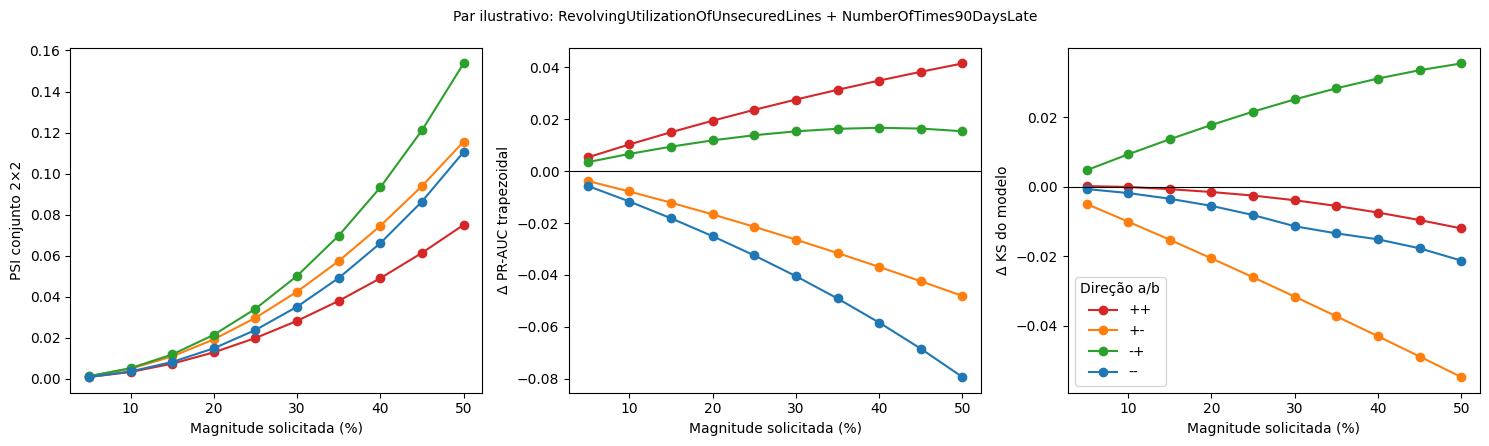

Legenda: quatro linhas correspondem aos sinais das duas margens altas. O par foi selecionado exploratoriamente pela maior variação absoluta de KS; não é validação independente.


In [13]:
# Exemplo escolhido pela maior magnitude de variação de KS na grade do mix.
pick=mix_pares.iloc[mix_pares.delta_ks_modelo.abs().argmax()]
example=mix_pares[(mix_pares.variavel_a==pick.variavel_a)&
                  (mix_pares.variavel_b==pick.variavel_b)]
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
colors={'++':'tab:red','+-':'tab:orange','-+':'tab:green','--':'tab:blue'}
for direction,d in example.groupby('direcao'):
    d=d.sort_values('intensidade_pct')
    axes[0].plot(d.intensidade_pct,d.psi_conjunto_2x2,'o-',label=direction,color=colors[direction])
    axes[1].plot(d.intensidade_pct,d.delta_prauc_trap,'o-',label=direction,color=colors[direction])
    axes[2].plot(d.intensidade_pct,d.delta_ks_modelo,'o-',label=direction,color=colors[direction])
for ax in axes[1:]:ax.axhline(0,color='black',lw=.8)
axes[0].set(xlabel='Magnitude solicitada (%)',ylabel='PSI conjunto 2×2')
axes[1].set(xlabel='Magnitude solicitada (%)',ylabel='Δ PR-AUC trapezoidal')
axes[2].set(xlabel='Magnitude solicitada (%)',ylabel='Δ KS do modelo')
axes[2].legend(title='Direção a/b')
fig.suptitle('Par ilustrativo: '+pick.variavel_a+' + '+pick.variavel_b,fontsize=10)
fig.tight_layout();plt.show()
print('Legenda: quatro linhas correspondem aos sinais das duas margens altas. '
      'O par foi selecionado exploratoriamente pela maior variação absoluta de KS; não é validação independente.')

## 8. Pares com valores alterados: 1.800 cenários em amostra piloto

Para conter o custo de previsão, sorteamos **5.000 linhas sem reposição** do holdout; os resultados desta trilha referem-se somente ao piloto. Cada par recebe quatro direções e dez magnitudes de 5% a 50%. A semente fixa a amostra. Como duas colunas são alteradas na mesma pessoa, **não** se reaproveita seu rótulo antigo para medir desempenho; ficam apenas PSI das entradas e scores, movimento de score e decisões que cruzam 0,50. A alteração deixa as outras oito entradas fixas; os notebooks 05, 06 e 11 investigam mecanismos com perfis inteiros ou propagação condicional. Verifique `mudanca_realizada_*` e `n_alterados_*` porque arredondamento pode anular o choque em contagens usuais.
A fração de linhas com pelo menos uma das duas entradas fora dos mínimos/máximos do treino é guardada em `fora_suporte_treino_frac` e seu delta contra o piloto basal. Consulte-a antes de interpretar os cenários de ±50%.


In [14]:
rng = np.random.default_rng(SEED)
ids = np.sort(rng.choice(len(X_hold), size=min(5000, len(X_hold)), replace=False))
X_pilot = X_hold.iloc[ids].reset_index(drop=True)
score_pilot = score_hold[ids]
pair_value_rows = []
for a, b in combinations(FEATURES, 2):
    for magnitude in MAGNITUDES:
        for sign_a, sign_b in product((-1, 1), repeat=2):
            ra, rb = sign_a * magnitude, sign_b * magnitude
            scenario = change_values(X_pilot, {a: ra, b: rb})
            new_score = predict(scenario)
            result = response_metrics(score_pilot, new_score)
            result.update({
                'variavel_a': a, 'variavel_b': b,
                'direcao': ('+' if sign_a > 0 else '-') + ('+' if sign_b > 0 else '-'),
                'intensidade_pct': 100 * magnitude,
                'mudanca_solicitada_a_pct': 100 * ra,
                'mudanca_solicitada_b_pct': 100 * rb,
                'mudanca_realizada_a_pct': realized_mean_change(X_pilot[a], scenario[a]),
                'mudanca_realizada_b_pct': realized_mean_change(X_pilot[b], scenario[b]),
                'psi_a': psi_feature(X_pilot[a], scenario[a]),
                'psi_b': psi_feature(X_pilot[b], scenario[b]),
                'psi_conjunto_2x2': psi_joint_high(X_pilot[a], X_pilot[b], scenario[a], scenario[b]),
                'n_alterados_a': int(np.sum(~np.isclose(X_pilot[a], scenario[a], equal_nan=True))),
                'n_alterados_b': int(np.sum(~np.isclose(X_pilot[b], scenario[b], equal_nan=True))),
                'fora_suporte_treino_frac': fraction_outside_training_support(scenario,[a,b]),
                'delta_fora_suporte_treino_frac': (fraction_outside_training_support(scenario,[a,b])
                                                   -fraction_outside_training_support(X_pilot,[a,b])),
            })
            pair_value_rows.append(result)
valores_pares = pd.DataFrame(pair_value_rows)
valores_pares.to_csv(OUT / 'resultados_percentuais_valores_pares.csv', index=False)
display(valores_pares[['variavel_a','variavel_b','direcao','intensidade_pct','psi_a','psi_b',
                       'psi_conjunto_2x2','mudanca_absoluta_score_media','troca_decisao']].round(5).head(12))
assert len(valores_pares)==45*4*len(MAGNITUDES)
print('Cenários de valores em pares:', len(valores_pares))

,variavel_a,variavel_b,direcao,intensidade_pct,psi_a,psi_b,psi_conjunto_2x2,mudanca_absoluta_score_media,troca_decisao
0,RevolvingUtilizationOfUnsecuredLines,age,--,5.0,0.23197,0.03448,0.03263,0.01059,0.0148
1,RevolvingUtilizationOfUnsecuredLines,age,-+,5.0,0.23197,0.03773,0.02162,0.01225,0.0166
2,RevolvingUtilizationOfUnsecuredLines,age,+-,5.0,0.00589,0.03448,0.02899,0.01803,0.0242
3,RevolvingUtilizationOfUnsecuredLines,age,++,5.0,0.00589,0.03773,0.02405,0.01468,0.0162
4,RevolvingUtilizationOfUnsecuredLines,age,--,10.0,0.24638,0.15842,0.12570,0.01804,0.0228
5,RevolvingUtilizationOfUnsecuredLines,age,-+,10.0,0.24638,0.13697,0.07996,0.02192,0.0276
6,RevolvingUtilizationOfUnsecuredLines,age,+-,10.0,0.01845,0.15842,0.11342,0.03003,0.0394
7,RevolvingUtilizationOfUnsecuredLines,age,++,10.0,0.01845,0.13697,0.09031,0.02046,0.0196
8,RevolvingUtilizationOfUnsecuredLines,age,--,15.0,0.26597,0.33244,0.24822,0.02523,0.0298
9,RevolvingUtilizationOfUnsecuredLines,age,-+,15.0,0.26597,0.25273,0.14225,0.03163,0.0428


Cenários de valores em pares: 1800


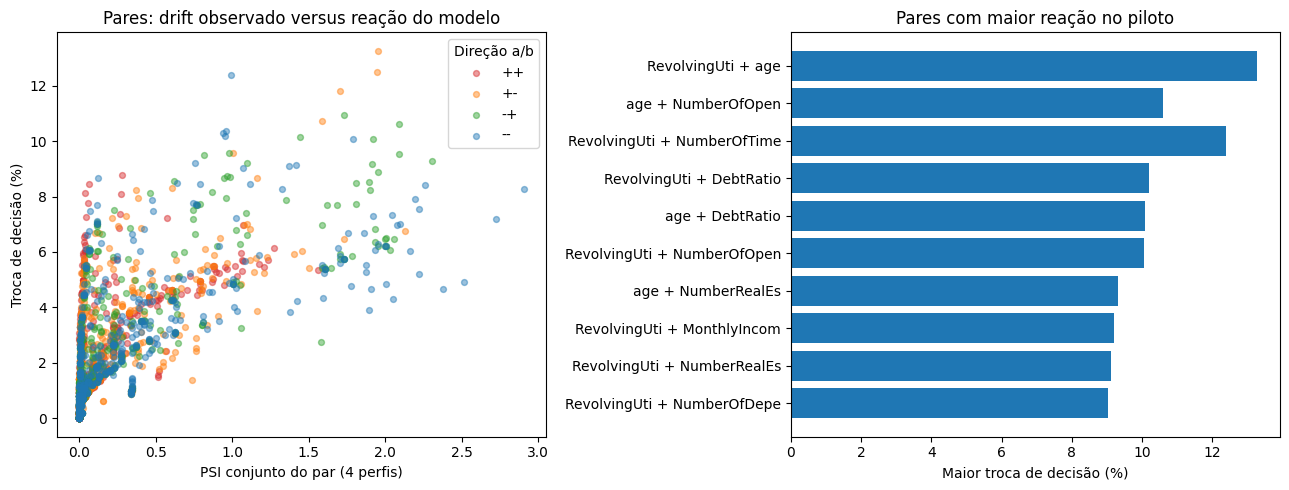

Legenda: cores indicam aumentar/reduzir o primeiro e o segundo valor. Cada ponto usa 5.000 registros e uma intensidade de 5%, 10%, …, 50%. A barra é a maior taxa de troca entre as 40 combinações de direção/intensidade do par.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {'++':'tab:red','+-':'tab:orange','-+':'tab:green','--':'tab:blue'}
for direction, d in valores_pares.groupby('direcao'):
    axes[0].scatter(d['psi_conjunto_2x2'], 100*d['troca_decisao'],
                    alpha=0.45, s=18, color=colors[direction], label=direction)
axes[0].set(xlabel='PSI conjunto do par (4 perfis)', ylabel='Troca de decisão (%)',
            title='Pares: drift observado versus reação do modelo')
axes[0].legend(title='Direção a/b')
worst = valores_pares.groupby(['variavel_a','variavel_b'], as_index=False)['troca_decisao'].max()
worst = worst.sort_values('troca_decisao', ascending=False).head(12)
labels = worst['variavel_a'].str[:12] + ' + ' + worst['variavel_b'].str[:12]
axes[1].barh(labels[::-1], 100*worst['troca_decisao'][::-1])
axes[1].set(xlabel='Maior troca de decisão (%)', title='Pares com maior reação no piloto')
plt.tight_layout()
plt.show()
print('Legenda: cores indicam aumentar/reduzir o primeiro e o segundo valor. Cada ponto usa 5.000 registros e uma intensidade de 5%, 10%, …, 50%. A barra é a maior taxa de troca entre as 40 combinações de direção/intensidade do par.')

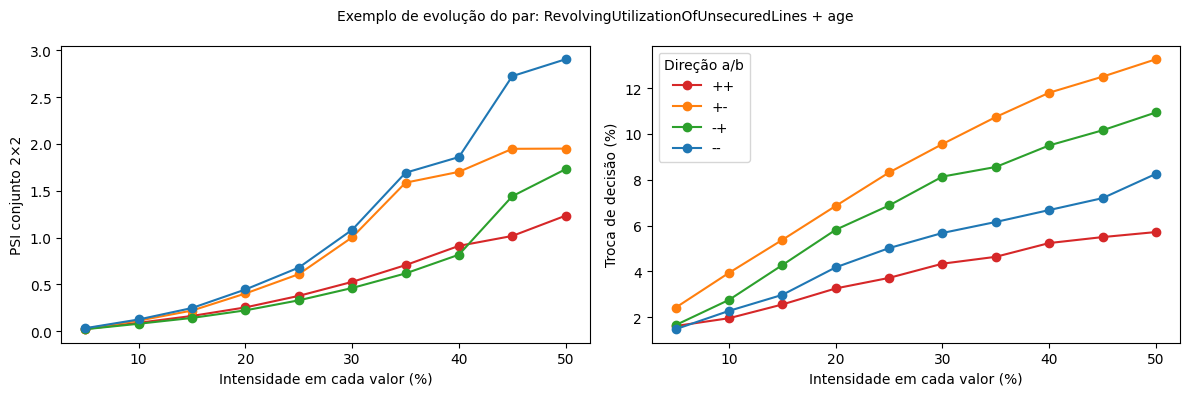

Legenda: 40 cenários do mesmo par, com 5% a 50% em passos de 5% em quatro direções. O par foi escolhido pela maior troca de decisão da grade piloto (descrição exploratória).


In [16]:
pick = valores_pares.iloc[valores_pares['troca_decisao'].argmax()]
example = valores_pares[(valores_pares['variavel_a'] == pick['variavel_a']) &
                        (valores_pares['variavel_b'] == pick['variavel_b'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for direction, d in example.groupby('direcao'):
    d = d.sort_values('intensidade_pct')
    axes[0].plot(d['intensidade_pct'], d['psi_conjunto_2x2'], 'o-', color=colors[direction], label=direction)
    axes[1].plot(d['intensidade_pct'], 100*d['troca_decisao'], 'o-', color=colors[direction], label=direction)
axes[0].set(xlabel='Intensidade em cada valor (%)', ylabel='PSI conjunto 2×2')
axes[1].set(xlabel='Intensidade em cada valor (%)', ylabel='Troca de decisão (%)')
axes[1].legend(title='Direção a/b')
fig.suptitle('Exemplo de evolução do par: ' + pick['variavel_a'] + ' + ' + pick['variavel_b'], fontsize=10)
plt.tight_layout()
plt.show()
print('Legenda: 40 cenários do mesmo par, com 5% a 50% em passos de 5% em quatro direções. O par foi escolhido pela maior troca de decisão da grade piloto (descrição exploratória).')

## 9. Onde ocorreram as maiores mudanças das quatro métricas?

Em lugar de uma “primeira falha” baseada em números arbitrários, resumimos, **para cada variável/par e direção**, o ponto da grade com resposta mais desfavorável em Brier, AUC ROC, PR-AUC trapezoidal e KS do modelo. Para Brier, desfavorável significa maior $\Delta$; para as três métricas de discriminação, menor $\Delta$. A tabela preserva o **delta com sinal**, a intensidade solicitada e o PSI realizado naquele ponto. Um delta orientado negativo indica que até o extremo menos favorável melhorou a métrica na grade. Selecionar o pior entre muitos cenários cria viés de seleção; este ranking é descritivo e deve ser reavaliado em dados rotulados independentes.

Não há corte, semáforo, aprovação ou estimativa pontual de “tolerância máxima”. Para responder “quanto drift o modelo suporta?” com uma decisão operacional, será preciso definir materialidade no seu negócio e validá-la em safras futuras. Aqui mostramos a superfície empírica de **drift versus resposta**, permitindo estudar os valores maiores de AUC/PR-AUC/KS solicitados.

Extremos univariados por direção:

,variavel,direcao,metrica,intensidade_solicitada_pct,psi_realizado,delta_metrica,n_efetivo_no_extremo
54,NumberOfTimes90DaysLate,-,prauc_trap,50.0,0.02047,-0.05781,22166.55642
70,RevolvingUtilizationOfUnsecuredLines,-,prauc_trap,50.0,0.09256,-0.05355,20769.23077
38,NumberOfTime30-59DaysPastDueNotWorse,-,prauc_trap,50.0,0.06417,-0.04957,21452.99145
46,NumberOfTime60-89DaysPastDueNotWorse,-,prauc_trap,50.0,0.01864,-0.04870,22196.44158
64,RevolvingUtilizationOfUnsecuredLines,+,brier,50.0,0.06672,0.03105,20769.23077
55,NumberOfTimes90DaysLate,-,ks_modelo,50.0,0.02047,-0.03006,22166.55642
47,NumberOfTime60-89DaysPastDueNotWorse,-,ks_modelo,50.0,0.01864,-0.02333,22196.44158
32,NumberOfTime30-59DaysPastDueNotWorse,+,brier,50.0,0.04148,0.02067,21452.99145
39,NumberOfTime30-59DaysPastDueNotWorse,-,ks_modelo,50.0,0.06417,-0.01875,21452.99145
67,RevolvingUtilizationOfUnsecuredLines,+,ks_modelo,50.0,0.06672,-0.01805,20769.23077


Extremos em pares por direção:


,variavel_a,variavel_b,direcao,metrica,intensidade_solicitada_pct,psi_realizado,delta_metrica,n_efetivo_no_extremo
526,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,--,prauc_trap,50.0,0.14443,-0.08614,20230.77273
398,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,--,prauc_trap,50.0,0.03128,-0.08546,22006.75323
334,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,--,prauc_trap,50.0,0.07310,-0.08526,21333.75869
542,RevolvingUtilizationOfUnsecuredLines,NumberOfTime60-89DaysPastDueNotWorse,--,prauc_trap,50.0,0.11244,-0.08059,20688.68520
558,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,--,prauc_trap,50.0,0.11051,-0.07933,20716.41612
318,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,--,prauc_trap,50.0,0.07035,-0.07395,21374.42727
298,NumberOfTime30-59DaysPastDueNotWorse,NumberOfOpenCreditLinesAndLoans,-+,prauc_trap,50.0,0.16157,-0.06778,19348.35382
78,DebtRatio,NumberOfTimes90DaysLate,--,prauc_trap,50.0,0.12774,-0.06637,20435.81595
214,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,+-,prauc_trap,50.0,0.10482,-0.06301,20258.72896
346,NumberOfTime30-59DaysPastDueNotWorse,NumberRealEstateLoansOrLines,-+,prauc_trap,50.0,0.15265,-0.06193,19521.19462


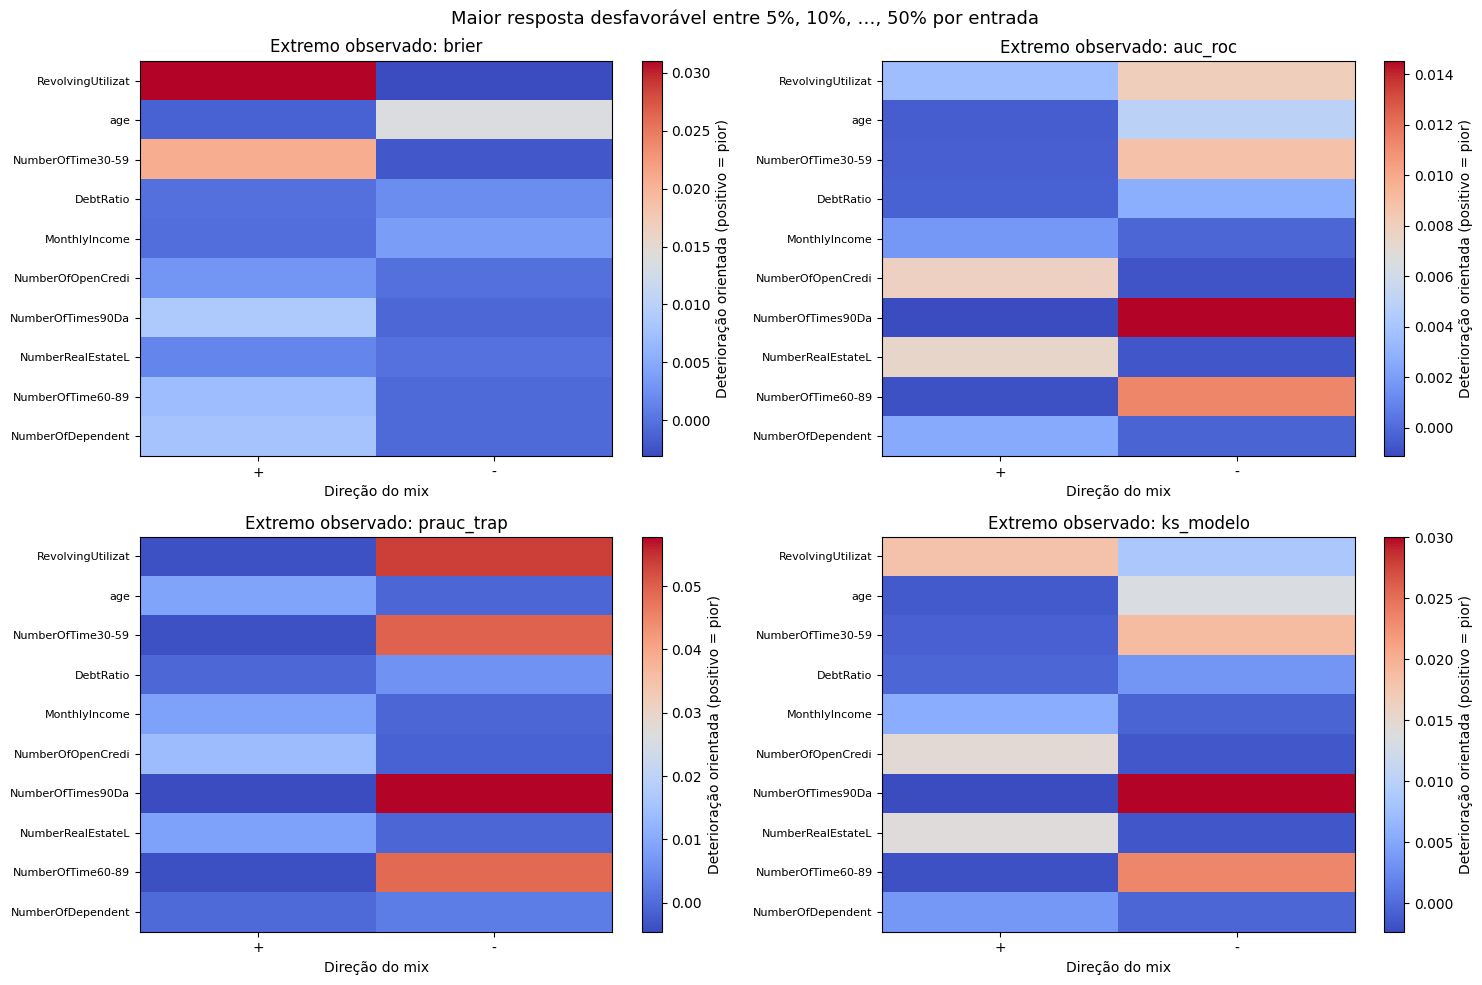

Legenda: cada célula é o ponto mais desfavorável daquela entrada/direção na grade, após orientar o sinal da métrica. PSI e intensidade correspondentes estão no CSV; valores negativos significam melhoria em todos os dez passos daquele grupo.


In [17]:
CENTRAIS={'brier':('delta_brier',1),
          'auc_roc':('delta_auc_roc',-1),
          'prauc_trap':('delta_prauc_trap',-1),
          'ks_modelo':('delta_ks_modelo',-1)}

def resumir_extremos(frame,group_cols,intensity_col,psi_col,trilha):
    rows=[]
    for key,d in frame.groupby(group_cols,dropna=False):
        if not isinstance(key,tuple): key=(key,)
        for metrica,(delta_col,sinal) in CENTRAIS.items():
            orientada=sinal*d[delta_col].to_numpy()
            row=d.iloc[int(np.argmax(orientada))]
            rows.append({'trilha':trilha,**dict(zip(group_cols,key)),
                         'metrica':metrica,'intensidade_solicitada_pct':float(row[intensity_col]),
                         'psi_realizado':float(row[psi_col]),
                         'delta_metrica':float(row[delta_col]),
                         'deterioracao_orientada':float(sinal*row[delta_col]),
                         'n_cenarios_no_grupo':len(d),
                         'n_efetivo_no_extremo':float(row.n_efetivo)})
    return pd.DataFrame(rows)

mix_uni_resumo=mix_uni.assign(direcao=np.where(mix_uni.mudanca_relativa_pct>0,'+','-'),
                              intensidade_abs_pct=mix_uni.mudanca_relativa_pct.abs())
resumo_univariado=resumir_extremos(mix_uni_resumo,['variavel','direcao'],
                                   'intensidade_abs_pct','psi_variavel','mix_univariado_com_Y')
resumo_pares=resumir_extremos(mix_pares,['variavel_a','variavel_b','direcao'],
                              'intensidade_pct','psi_conjunto_2x2','mix_par_com_Y')
resumo=pd.concat([resumo_univariado,resumo_pares],ignore_index=True)
assert len(resumo_univariado)==10*2*4
assert len(resumo_pares)==45*4*4
resumo.to_csv(OUT/'resumo_extremos_percentuais_sem_limite.csv',index=False,encoding='utf-8-sig')
print('Extremos univariados por direção:')
display(resumo_univariado.sort_values('deterioracao_orientada',ascending=False)
        [['variavel','direcao','metrica','intensidade_solicitada_pct',
          'psi_realizado','delta_metrica','n_efetivo_no_extremo']].head(20).round(5))
print('Extremos em pares por direção:')
display(resumo_pares.sort_values('deterioracao_orientada',ascending=False)
        [['variavel_a','variavel_b','direcao','metrica','intensidade_solicitada_pct',
          'psi_realizado','delta_metrica','n_efetivo_no_extremo']].head(20).round(5))

fig,axes=plt.subplots(2,2,figsize=(15,10))
for ax,metrica in zip(axes.flat,CENTRAIS):
    d=resumo_univariado[resumo_univariado.metrica==metrica]
    piv=d.pivot(index='variavel',columns='direcao',values='deterioracao_orientada').reindex(FEATURES)
    im=ax.imshow(piv.to_numpy(),aspect='auto',cmap='coolwarm')
    ax.set_xticks([0,1],piv.columns)
    ax.set_yticks(range(len(FEATURES)),[f[:17] for f in FEATURES],fontsize=8)
    ax.set(title=f'Extremo observado: {metrica}',xlabel='Direção do mix')
    fig.colorbar(im,ax=ax,label='Deterioração orientada (positivo = pior)')
fig.suptitle('Maior resposta desfavorável entre 5%, 10%, …, 50% por entrada',fontsize=13)
fig.tight_layout();plt.show()
print('Legenda: cada célula é o ponto mais desfavorável daquela entrada/direção na grade, '
      'após orientar o sinal da métrica. PSI e intensidade correspondentes estão no CSV; '
      'valores negativos significam melhoria em todos os dez passos daquele grupo.')

## 10. Interpretação e limites ao transportar o método

1. **Leia o mecanismo antes do número.** `resultados_percentuais_mix_univariado.csv` e `resultados_percentuais_mix_pares.csv` são simulações de composição com rótulos válidos **condicionalmente** a $P(Y\mid X)$ estável. `resultados_percentuais_valores_univariado.csv`, `resultados_percentuais_valores_pares.csv` e `resultados_transicoes_atraso.csv` são alterações contrafactuais de entradas: seus PSI, scores e trocas de decisão não são medidas de acerto.
2. **Leia o efeito realizado.** 5% aplicado a uma entrada não é PSI 0,05. Nas contagens, arredondamento e zeros podem anular o choque. Em mix, a participação é relativa, não um aumento em pontos percentuais. Em pares, as duas participações altas são ajustadas por IPF e o PSI conjunto se refere somente à tabela 2×2.
3. **Compare as quatro métricas centrais sem confundi-las.** Brier é erro quadrático; AUC ROC, PR-AUC trapezoidal e KS medem aspectos diferentes da separação. PR-AUC é sensível à prevalência. AP fica separada. Recall e precisão usam somente o corte 0,50 como referência; nenhuma delas interrompe a grade.
4. **Avalie suporte e incerteza.** Consulte ESS, tamanho das quatro células, PSI das demais entradas e cenários extremos. Os máximos de deterioração foram escolhidos após inspecionar muitos cenários no mesmo holdout; faça bootstrap pareado para trajetórias pré-especificadas e, sobretudo, confirmação em uma safra rotulada posterior.
5. **Replicação.** Substitua as dez colunas, rótulo e artefato por seu contexto; congele split, bins e modelo; escolha grupos/transformações defensáveis; mantenha uma grade simétrica; reporte unidades, mudanças realizadas, drift e validade do desfecho. Estabeleça limites de negócio apenas quando houver materialidade, custo e horizonte de rótulo definidos externamente.

**Fundamentação:** [Mandoline: avaliação por reponderação sob mudança de distribuição](https://proceedings.mlr.press/v139/chen21i.html); [Subbaswamy et al.: estabilidade sob deslocamentos](https://proceedings.mlr.press/v130/subbaswamy21a.html); [Blanchet et al.: perturbações e deterioração](https://proceedings.mlr.press/v235/blanchet24a.html); [NIST AI RMF Playbook: medição e monitoramento](https://airc.nist.gov/airmf-resources/playbook/measure/); [scikit-learn: definições das métricas](https://scikit-learn.org/stable/modules/model_evaluation.html).